In [1]:
import json
from pathlib import Path

path = Path("/Users/chennupatigunadeep/Downloads/Capstone/DataSets/Segmentation/teeth_bbox.json")  # edit this
with open(path) as f:
    data = json.load(f)

print(f"Top-level type: {type(data).__name__}")
print(f"Length: {len(data) if hasattr(data, '__len__') else 'N/A'}")

if isinstance(data, list):
    first = data[0]
    print(f"\nFirst item type: {type(first).__name__}")
    print(f"First item TOP-LEVEL KEYS: {list(first.keys()) if isinstance(first, dict) else 'N/A'}")
    # Print non-object fields to find the image identifier
    for k, v in first.items():
        if k != "Label":
            print(f"  {k}: {v}")
    # Count objects
    if "Label" in first and "objects" in first["Label"]:
        print(f"\n  Objects in first entry: {len(first['Label']['objects'])}")

Top-level type: list
Length: 1000

First item type: dict
First item TOP-LEVEL KEYS: ['Label', 'External ID']
  External ID: 797.jpg

  Objects in first entry: 31


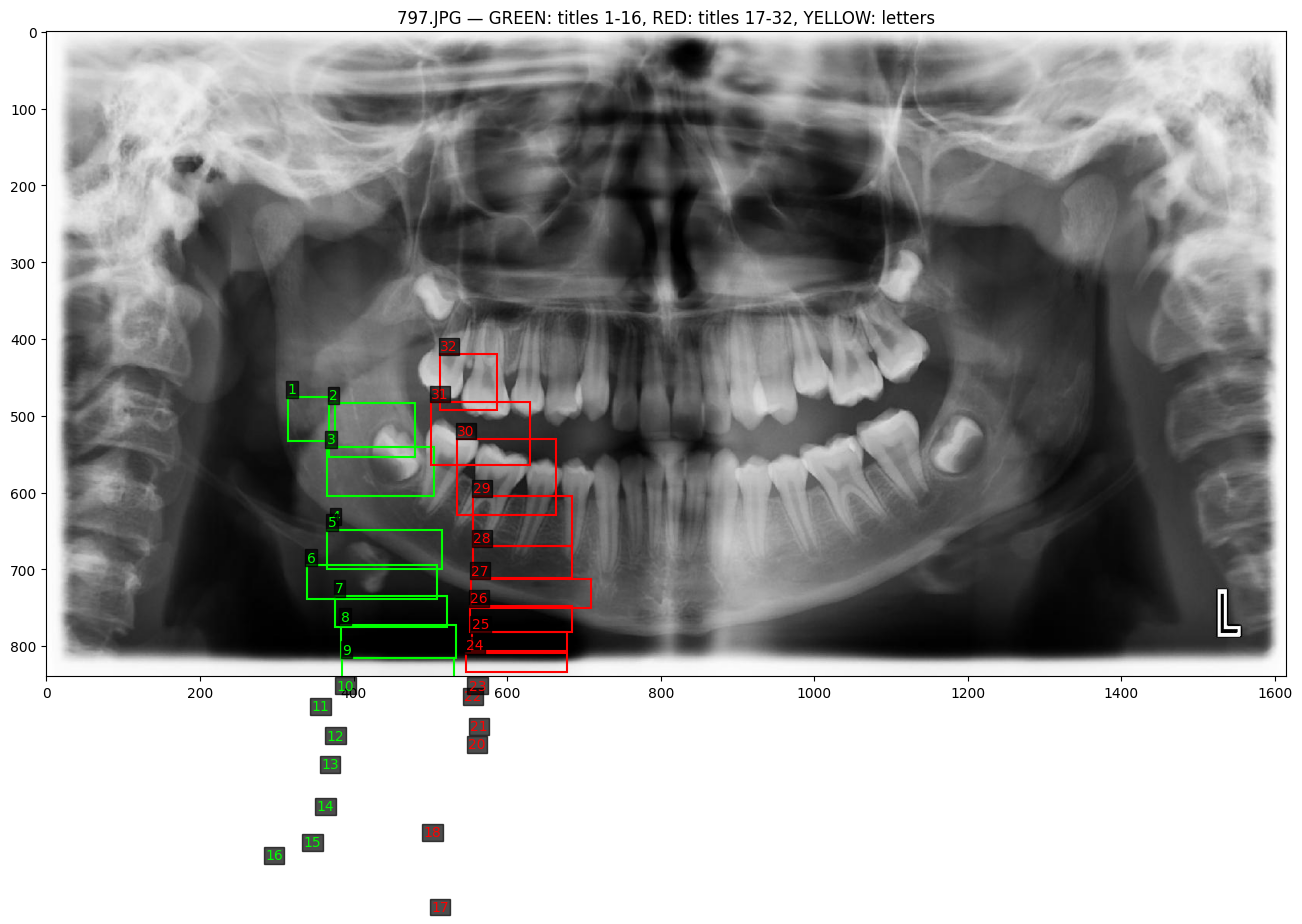

In [4]:
# Debug visualization for a single radiograph (797)
import json
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image

TUFTS_ROOT = Path("/Users/chennupatigunadeep/Downloads/Capstone/DataSets")

with open(TUFTS_ROOT / "Segmentation" / "teeth_bbox.json") as f:
    data = json.load(f)

# Find the entry (case in filenames differs: .jpg vs .JPG)
external_id = "797.jpg"
target = next((entry for entry in data if entry.get("External ID") == external_id), None)
if target is None:
    raise ValueError(f"Entry with External ID {external_id!r} not found in teeth_bbox.json")

stem = Path(external_id).stem  # e.g. '797'
radiographs_dir = TUFTS_ROOT / "Radiographs"

# Prefer exact matches first
candidates = [
    radiographs_dir / f"{stem}.JPG",
    radiographs_dir / f"{stem}.jpg",
    radiographs_dir / f"{stem}.PNG",
    radiographs_dir / f"{stem}.png",
    radiographs_dir / f"{stem}.jpeg",
    radiographs_dir / f"{stem}.JPEG",
    radiographs_dir / f"{stem}.tif",
    radiographs_dir / f"{stem}.TIF",
    radiographs_dir / f"{stem}.tiff",
    radiographs_dir / f"{stem}.TIFF",
 ]

img_path = next((p for p in candidates if p.exists()), None)
if img_path is None:
    # Fallback: any extension under Radiographs/ (case-insensitive by scanning)
    img_path = next((p for p in radiographs_dir.glob(f"{stem}.*") if p.is_file()), None)
if img_path is None:
    raise FileNotFoundError(f"Could not find image for stem={stem!r} under {radiographs_dir}")

img = Image.open(img_path).convert("RGB")

fig, ax = plt.subplots(figsize=(16, 10))
ax.imshow(img)
for obj in target["Label"]["objects"]:
    title = str(obj["title"])
    x1, y1, x2, y2 = obj["bounding box"]
    color = (
        "lime"
        if title.isdigit() and int(title) <= 16
        else "red"
        if title.isdigit()
        else "yellow"
    )
    ax.add_patch(
        plt.Rectangle(
            (x1, y1), x2 - x1, y2 - y1, linewidth=1.5, edgecolor=color, facecolor="none"
        )
    )
    ax.text(
        x1,
        y1 - 5,
        title,
        color=color,
        fontsize=10,
        bbox=dict(facecolor="black", alpha=0.7, pad=1),
    )
ax.set_title(f"{img_path.name} — GREEN: titles 1-16, RED: titles 17-32, YELLOW: letters")
plt.savefig(f"debug_{stem}.png", dpi=120, bbox_inches="tight")
plt.show()

In [7]:
from PIL import Image

img_path = Path("/Users/chennupatigunadeep/Downloads/Capstone/DataSets/Radiographs/797.JPG")  # your 797 path
img = Image.open(img_path)
print(f"Image dimensions: W={img.width} x H={img.height}")
print(f"Image mode: {img.mode}")

# Check if image has EXIF orientation metadata
try:
    exif = img.getexif()
    if 274 in exif:  # 274 = Orientation tag
        print(f"EXIF orientation: {exif[274]}")
    else:
        print("No EXIF orientation tag")
except:
    print("No EXIF data")

Image dimensions: W=1615 x H=840
Image mode: RGB
No EXIF orientation tag


Original image: 1615 x 840


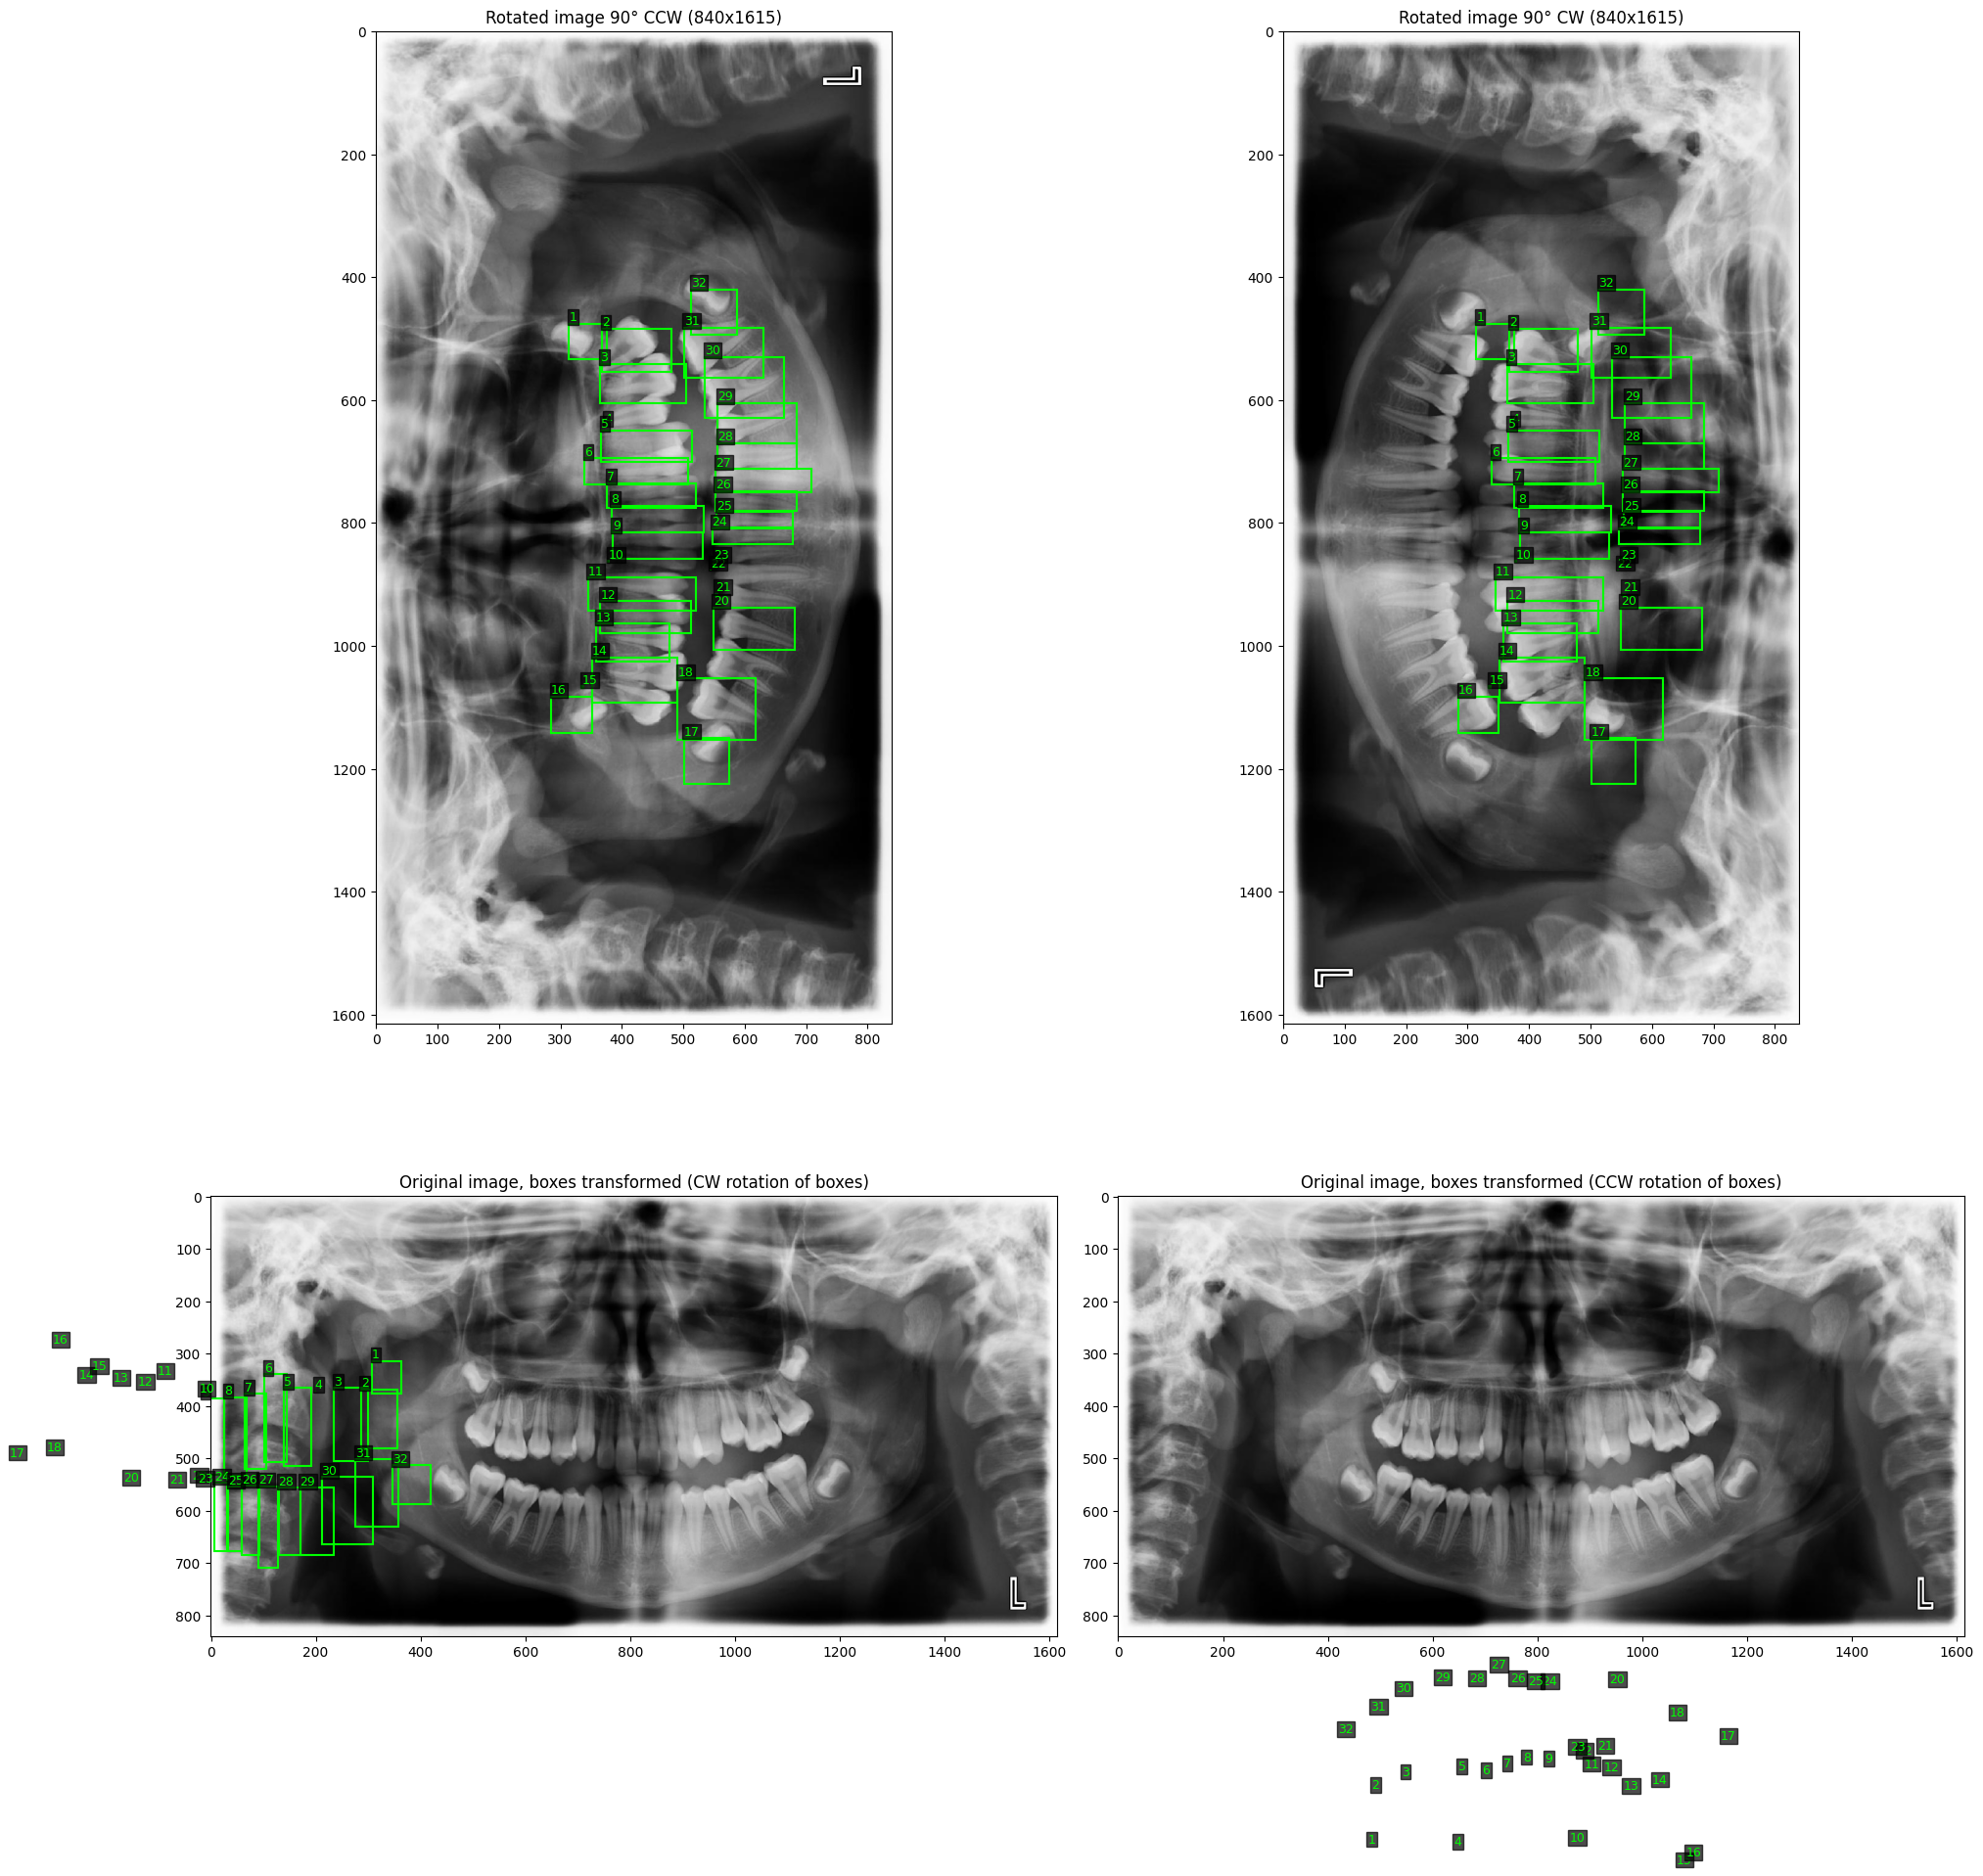

In [8]:
import matplotlib.pyplot as plt
from PIL import Image
import json
from pathlib import Path

TUFTS_ROOT = Path("/Users/chennupatigunadeep/Downloads/Capstone/DataSets")

with open(TUFTS_ROOT / "Segmentation" / "teeth_bbox.json") as f:
    data = json.load(f)

target = next(e for e in data if e["External ID"] == "797.jpg")
img_path = TUFTS_ROOT / "Radiographs" / "797.JPG"
if not img_path.exists():
    img_path = TUFTS_ROOT / "Radiographs" / "797.jpg"

img = Image.open(img_path).convert("RGB")
W, H = img.width, img.height
print(f"Original image: {W} x {H}")

boxes = target["Label"]["objects"]

fig, axes = plt.subplots(2, 2, figsize=(20, 20))

# Test 1: Rotate image 90° CCW (counterclockwise)
img_ccw = img.rotate(90, expand=True)
axes[0, 0].imshow(img_ccw)
for obj in boxes:
    x1, y1, x2, y2 = obj["bounding box"]
    axes[0, 0].add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1,
                         linewidth=1.5, edgecolor="lime", facecolor="none"))
    axes[0, 0].text(x1, y1-5, str(obj["title"]), color="lime", fontsize=9,
                    bbox=dict(facecolor="black", alpha=0.7, pad=1))
axes[0, 0].set_title(f"Rotated image 90° CCW ({img_ccw.width}x{img_ccw.height})")

# Test 2: Rotate image 90° CW (clockwise)
img_cw = img.rotate(-90, expand=True)
axes[0, 1].imshow(img_cw)
for obj in boxes:
    x1, y1, x2, y2 = obj["bounding box"]
    axes[0, 1].add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1,
                         linewidth=1.5, edgecolor="lime", facecolor="none"))
    axes[0, 1].text(x1, y1-5, str(obj["title"]), color="lime", fontsize=9,
                    bbox=dict(facecolor="black", alpha=0.7, pad=1))
axes[0, 1].set_title(f"Rotated image 90° CW ({img_cw.width}x{img_cw.height})")

# Test 3: Transform boxes instead — bbox CCW rotation
# If image went from portrait to landscape by rotating CCW:
#   new_x = y_orig
#   new_y = W_portrait - x_orig  (where W_portrait = H_landscape = 840)
axes[1, 0].imshow(img)
for obj in boxes:
    x1, y1, x2, y2 = obj["bounding box"]
    # Rotate box 90° CW to match image that was rotated 90° CW from annotation frame
    nx1 = H - y2  # H of displayed landscape = 840
    ny1 = x1
    nx2 = H - y1
    ny2 = x2
    axes[1, 0].add_patch(plt.Rectangle((nx1, ny1), nx2-nx1, ny2-ny1,
                         linewidth=1.5, edgecolor="lime", facecolor="none"))
    axes[1, 0].text(nx1, ny1-5, str(obj["title"]), color="lime", fontsize=9,
                    bbox=dict(facecolor="black", alpha=0.7, pad=1))
axes[1, 0].set_title("Original image, boxes transformed (CW rotation of boxes)")

# Test 4: Transform boxes — CCW rotation of boxes
axes[1, 1].imshow(img)
for obj in boxes:
    x1, y1, x2, y2 = obj["bounding box"]
    nx1 = y1
    ny1 = W - x2  # W of displayed landscape = 1615  
    nx2 = y2
    ny2 = W - x1
    axes[1, 1].add_patch(plt.Rectangle((nx1, ny1), nx2-nx1, ny2-ny1,
                         linewidth=1.5, edgecolor="lime", facecolor="none"))
    axes[1, 1].text(nx1, ny1-5, str(obj["title"]), color="lime", fontsize=9,
                    bbox=dict(facecolor="black", alpha=0.7, pad=1))
axes[1, 1].set_title("Original image, boxes transformed (CCW rotation of boxes)")

plt.tight_layout()
plt.savefig("rotation_test.png", dpi=100, bbox_inches="tight")
plt.show()

In [9]:
# Find 5 images with 30+ numeric teeth
targets = []
for entry in data:
    nums = [o for o in entry["Label"]["objects"] if str(o["title"]).isdigit()]
    if len(nums) >= 30:
        targets.append(entry["External ID"])
        if len(targets) >= 5:
            break

# Visualize each with 90° CW rotation
for ext_id in targets:
    img_path = TUFTS_ROOT / "Radiographs" / ext_id
    if not img_path.exists():
        img_path = TUFTS_ROOT / "Radiographs" / (Path(ext_id).stem + ".JPG")
    
    img = Image.open(img_path).convert("RGB")
    img_rot = img.rotate(-90, expand=True)  # 90° CW
    
    entry = next(e for e in data if e["External ID"] == ext_id)
    
    fig, ax = plt.subplots(figsize=(10, 16))
    ax.imshow(img_rot)
    for obj in entry["Label"]["objects"]:
        x1, y1, x2, y2 = obj["bounding box"]
        ax.add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1,
                     linewidth=1, edgecolor="lime", facecolor="none"))
    ax.set_title(f"{ext_id} rotated 90° CW")
    plt.savefig(f"verify_{Path(ext_id).stem}.png", dpi=80)
    plt.close()

print("Check verify_*.png files — all should show aligned boxes")

Check verify_*.png files — all should show aligned boxes


In [1]:
# /preprocessing/rotate_tufts_v2.py
# CORRECTED: 90° CCW rotation 

from pathlib import Path
from PIL import Image
from tqdm import tqdm
import shutil

TUFTS_ROOT = Path("/Users/chennupatigunadeep/Downloads/Capstone/DataSets")
SRC_DIR = TUFTS_ROOT / "Radiographs"
DST_DIR = TUFTS_ROOT / "Radiographs_rotated"

# Delete the previous (wrong) rotation output
if DST_DIR.exists():
    print(f"Removing previous (incorrectly rotated) directory: {DST_DIR}")
    shutil.rmtree(DST_DIR)

DST_DIR.mkdir(exist_ok=True)

src_files = []
for ext in ["*.jpg", "*.JPG", "*.png", "*.PNG"]:
    src_files.extend(SRC_DIR.glob(ext))
print(f"Found {len(src_files)} source images")

for src in tqdm(src_files, desc="Rotating CCW"):
    img = Image.open(src)
    if img.width > img.height:
        # CORRECTED: 90° CCW (was -90° CW before)
        img = img.rotate(90, expand=True)
    img.save(DST_DIR / src.name, quality=95)

sample = Image.open(next(DST_DIR.iterdir()))
print(f"\nVerification: rotated dimensions = {sample.width} x {sample.height}")
print("Expected: 840 x 1615")

Found 1000 source images


Rotating CCW: 100%|██████████| 1000/1000 [00:06<00:00, 155.75it/s]


Verification: rotated dimensions = 840 x 1615
Expected: 840 x 1615


In [12]:
# In Cell 2, add:
RADIOGRAPHS_DIR = TUFTS_ROOT / "Radiographs_rotated"  # NOT "Radiographs"

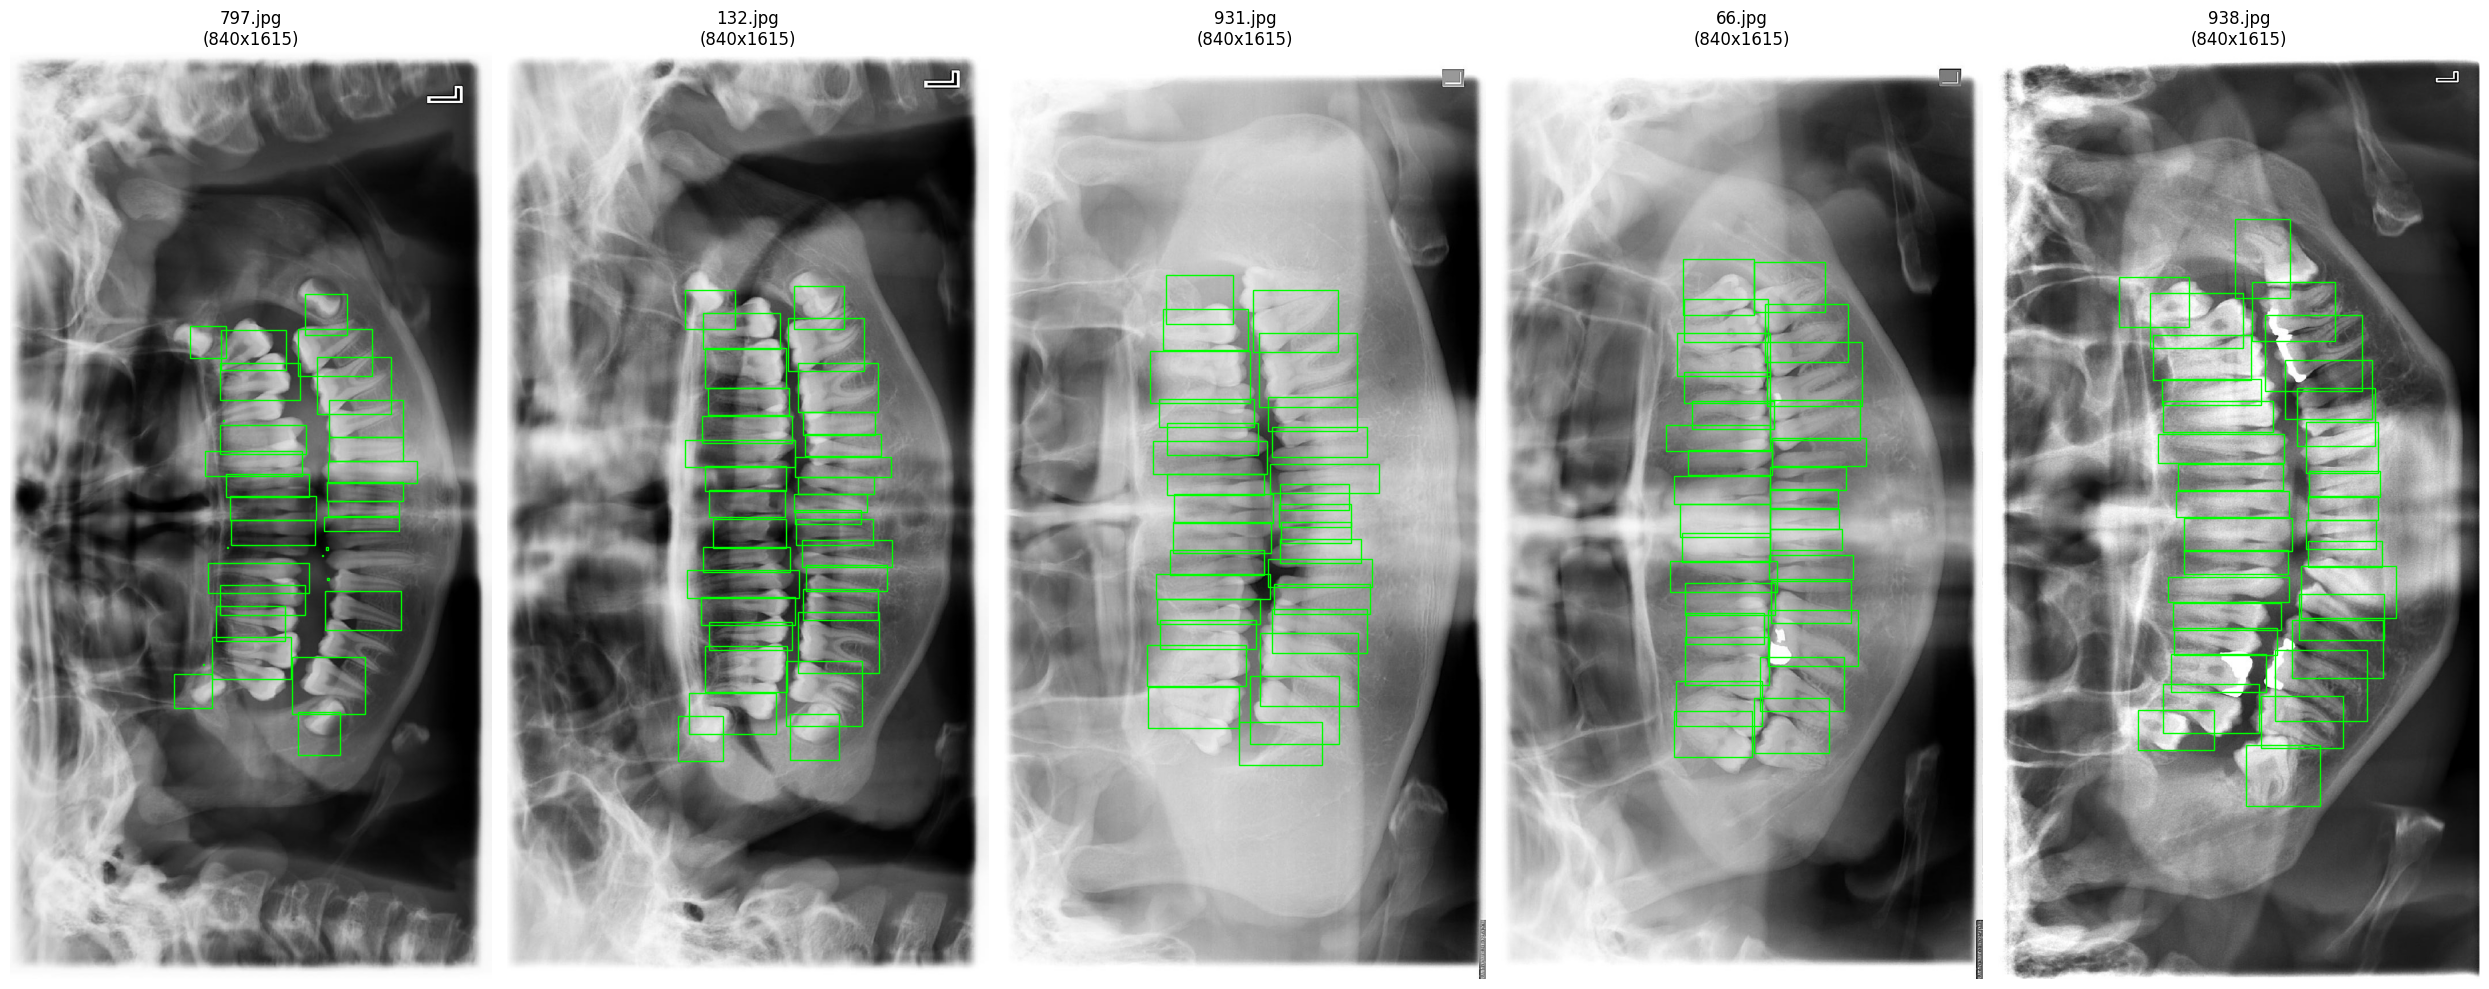

In [17]:
# Quick visual verification on 5 random rotated images
import json
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

TUFTS_ROOT = Path("/Users/chennupatigunadeep/Downloads/Capstone/DataSets")
ROTATED_DIR = TUFTS_ROOT / "Radiographs_rotated"

with open(TUFTS_ROOT / "Segmentation" / "teeth_bbox.json") as f:
    data = json.load(f)

# Pick 5 images with 30+ numeric teeth (likely adults with full dentition)
targets = []
for entry in data:
    nums = [o for o in entry["Label"]["objects"] if str(o["title"]).isdigit()]
    if 30 <= len(nums) <= 32:
        targets.append(entry["External ID"])
        if len(targets) >= 5:
            break

fig, axes = plt.subplots(1, 5, figsize=(25, 10))
for ax, ext_id in zip(axes, targets):
    img_path = ROTATED_DIR / ext_id
    if not img_path.exists():
        img_path = ROTATED_DIR / (Path(ext_id).stem + ".JPG")
    
    img = Image.open(img_path).convert("RGB")
    entry = next(e for e in data if e["External ID"] == ext_id)
    
    ax.imshow(img)
    for obj in entry["Label"]["objects"]:
        title = str(obj["title"])
        if not title.isdigit():
            continue
        x1, y1, x2, y2 = obj["bounding box"]
        ax.add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1,
                     linewidth=1, edgecolor="lime", facecolor="none"))
    ax.set_title(f"{ext_id}\n({img.width}x{img.height})")
    ax.axis("off")

plt.tight_layout()
plt.savefig("verify_rotation.png", dpi=80, bbox_inches="tight")
plt.show()

Original landscape: 1615 x 840
CCW rotation: 840 x 1615


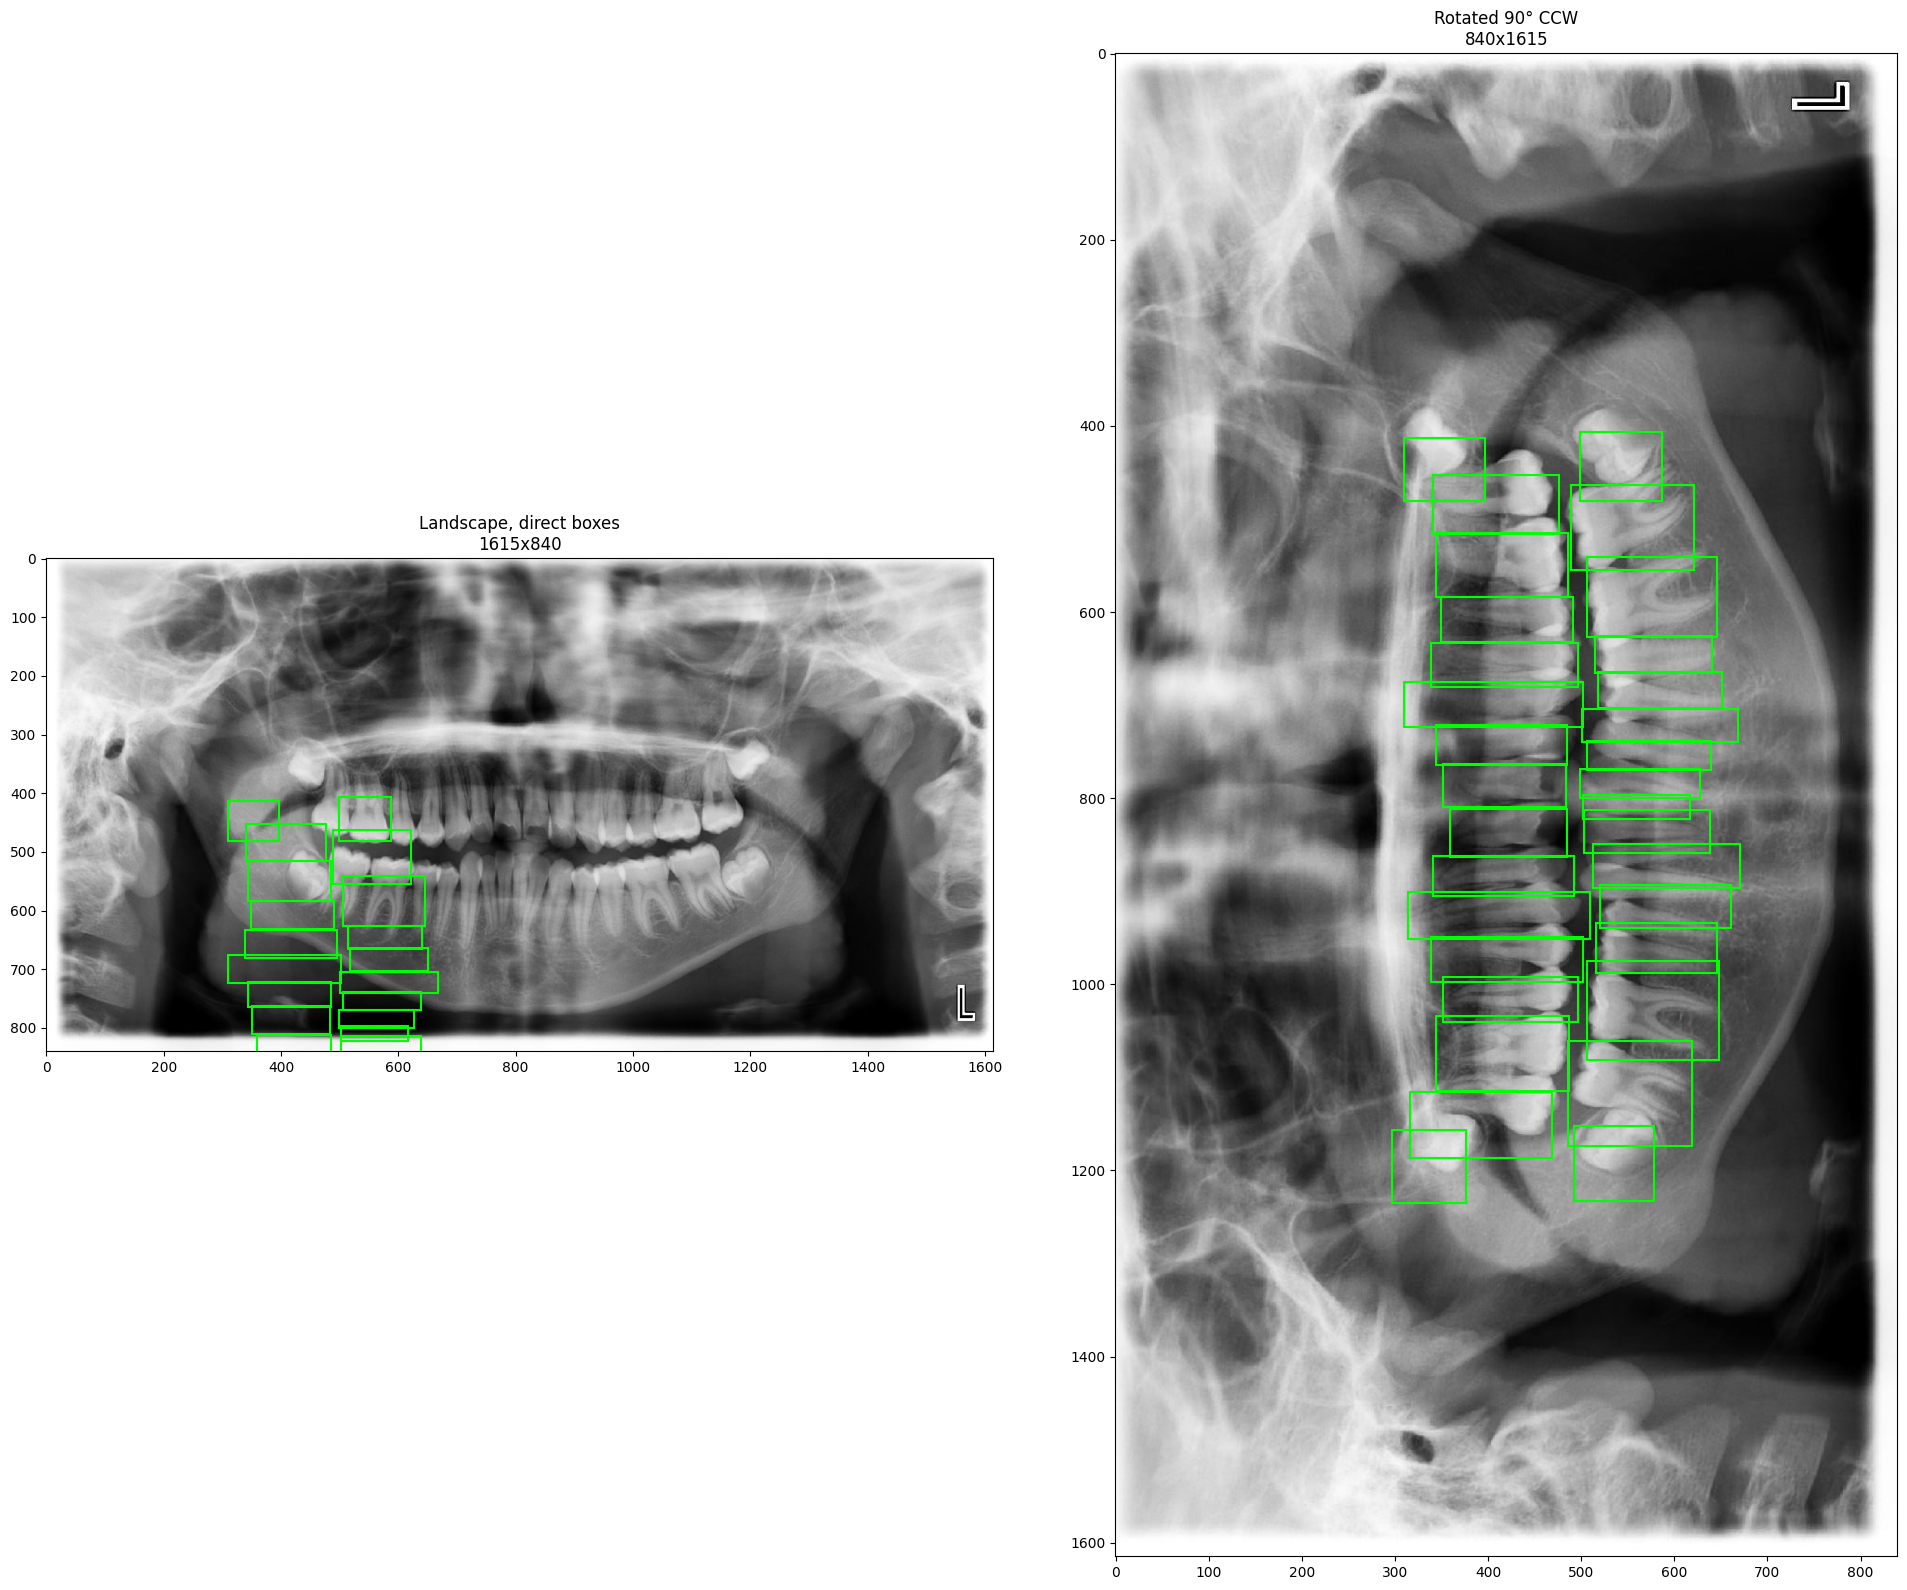

In [18]:
from PIL import Image
import matplotlib.pyplot as plt
import json
from pathlib import Path

TUFTS_ROOT = Path("/Users/chennupatigunadeep/Downloads/Capstone/DataSets")

with open(TUFTS_ROOT / "Segmentation" / "teeth_bbox.json") as f:
    data = json.load(f)

ext_id = "132.jpg"
entry = next(e for e in data if e["External ID"] == ext_id)

# Use ORIGINAL landscape image (not rotated)
img_path = TUFTS_ROOT / "Radiographs" / ext_id
if not img_path.exists():
    img_path = TUFTS_ROOT / "Radiographs" / (Path(ext_id).stem + ".JPG")

img_landscape = Image.open(img_path).convert("RGB")
print(f"Original landscape: {img_landscape.width} x {img_landscape.height}")

# Try CCW rotation instead of CW
img_ccw = img_landscape.rotate(90, expand=True)
print(f"CCW rotation: {img_ccw.width} x {img_ccw.height}")

fig, axes = plt.subplots(1, 2, figsize=(20, 16))

# Left: original landscape, boxes drawn directly (probably won't fit but shows us the layout)
axes[0].imshow(img_landscape)
for obj in entry["Label"]["objects"]:
    x1, y1, x2, y2 = obj["bounding box"]
    axes[0].add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1,
                     linewidth=1.5, edgecolor="lime", facecolor="none"))
axes[0].set_title(f"Landscape, direct boxes\n{img_landscape.width}x{img_landscape.height}")

# Right: CCW rotation
axes[1].imshow(img_ccw)
for obj in entry["Label"]["objects"]:
    x1, y1, x2, y2 = obj["bounding box"]
    axes[1].add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1,
                     linewidth=1.5, edgecolor="lime", facecolor="none"))
axes[1].set_title(f"Rotated 90° CCW\n{img_ccw.width}x{img_ccw.height}")

plt.tight_layout()
plt.savefig("rotation_compare.png", dpi=100, bbox_inches="tight")
plt.show()

Testing: 132.jpg
Annotation space X range: 336 to 592
Annotation space Y range: 444 to 1196
X span: 256
Y span: 752
Aspect: 0.34


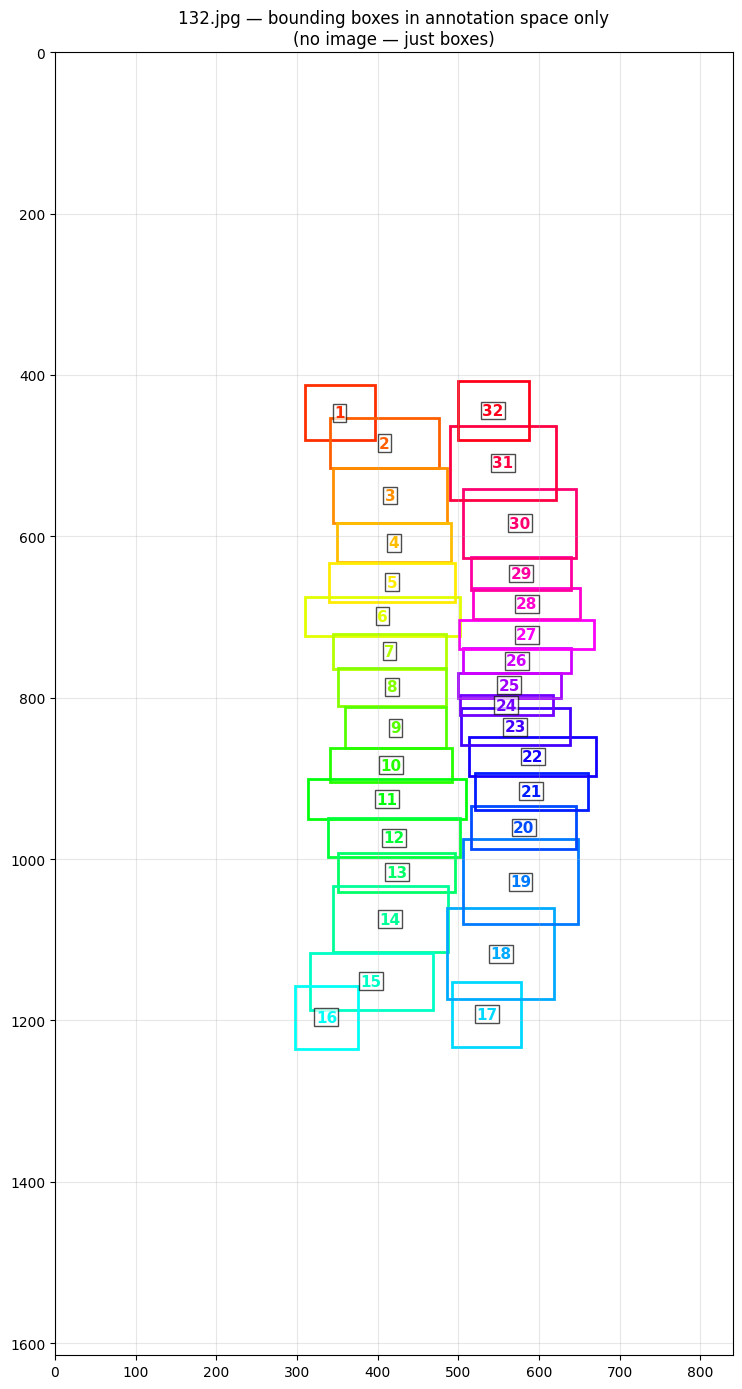

In [19]:
# Definitive rotation test using tooth count as oracle
# A correctly-rotated image should have:
# - Roughly equal counts of teeth in left and right half of image  
# - Clear bimodal distribution in Y (upper vs lower arch)
# - The L-marker in standard anatomical position

from PIL import Image
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np

TUFTS_ROOT = Path("/Users/chennupatigunadeep/Downloads/Capstone/DataSets")

with open(TUFTS_ROOT / "Segmentation" / "teeth_bbox.json") as f:
    data = json.load(f)

# Pick an image with exactly 32 numeric teeth (fully dentate adult)
for entry in data:
    nums = [o for o in entry["Label"]["objects"] if str(o["title"]).isdigit()]
    if len(nums) == 32:
        target = entry
        break

ext_id = target["External ID"]
print(f"Testing: {ext_id}")

# Analyze box center distribution (these are in annotation coordinate space)
centers = []
for obj in target["Label"]["objects"]:
    if not str(obj["title"]).isdigit():
        continue
    x1, y1, x2, y2 = obj["bounding box"]
    centers.append(((x1+x2)/2, (y1+y2)/2, int(obj["title"])))

# Print center distribution
xs = [c[0] for c in centers]
ys = [c[1] for c in centers]
print(f"Annotation space X range: {min(xs):.0f} to {max(xs):.0f}")
print(f"Annotation space Y range: {min(ys):.0f} to {max(ys):.0f}")
print(f"X span: {max(xs)-min(xs):.0f}")
print(f"Y span: {max(ys)-min(ys):.0f}")
print(f"Aspect: {(max(xs)-min(xs)) / (max(ys)-min(ys)):.2f}")

# Plot annotation space alone (no image)
fig, ax = plt.subplots(figsize=(8, 14))
for obj in target["Label"]["objects"]:
    if not str(obj["title"]).isdigit():
        continue
    x1, y1, x2, y2 = obj["bounding box"]
    title = int(obj["title"])
    color = plt.cm.hsv(title / 32)
    ax.add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1,
                 linewidth=2, edgecolor=color, facecolor="none"))
    ax.text((x1+x2)/2, (y1+y2)/2, str(title),
            color=color, fontsize=11, ha="center", va="center", weight="bold",
            bbox=dict(facecolor="white", alpha=0.7, pad=1))
ax.set_xlim(0, 840)
ax.set_ylim(1615, 0)  # inverted Y (image coordinates)
ax.set_aspect("equal")
ax.set_title(f"{ext_id} — bounding boxes in annotation space only\n(no image — just boxes)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("annotation_space_only.png", dpi=100, bbox_inches="tight")
plt.show()

Re-creating Radiographs_rotated/...
Created 1000 rotated images
Portrait image: 840 x 1615


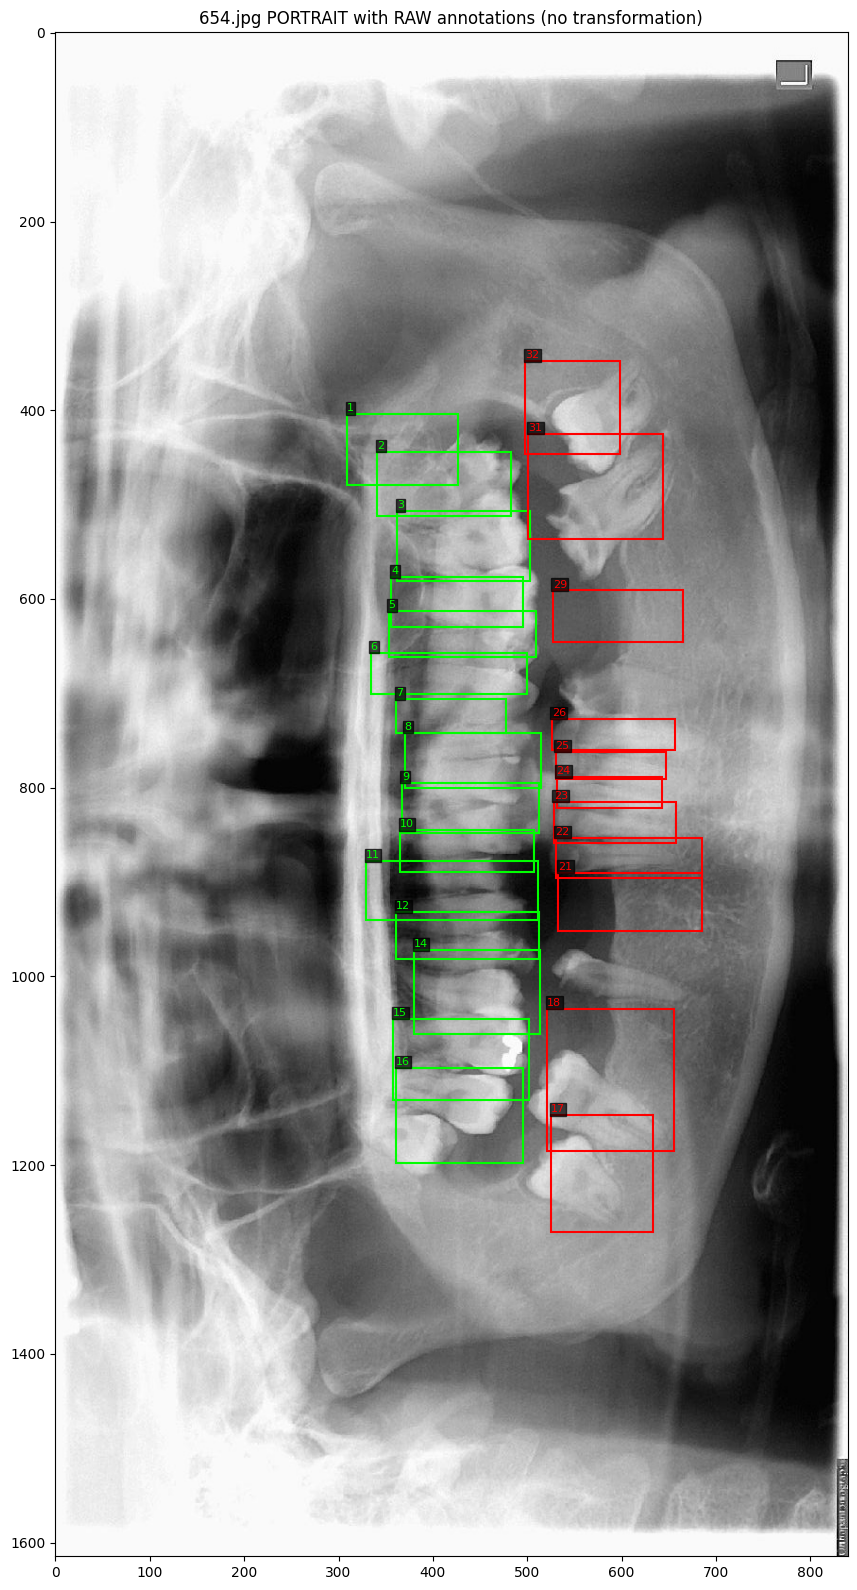

In [2]:
import json
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

TUFTS_ROOT = Path("/Users/chennupatigunadeep/Downloads/Capstone/DataSets")
ROTATED_DIR = TUFTS_ROOT / "Radiographs_rotated"  # RESTORED directory — do not delete

# If you already deleted it, recreate it now:
if not ROTATED_DIR.exists():
    print("Re-creating Radiographs_rotated/...")
    ROTATED_DIR.mkdir()
    for src in (TUFTS_ROOT / "Radiographs").glob("*"):
        if src.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            img = Image.open(src)
            if img.width > img.height:
                img = img.rotate(90, expand=True)  # 90° CCW
            img.save(ROTATED_DIR / src.name, quality=95)
    print(f"Created {len(list(ROTATED_DIR.iterdir()))} rotated images")

with open(TUFTS_ROOT / "Segmentation" / "teeth_bbox.json") as f:
    data = json.load(f)

# 654.jpg in portrait with raw annotations
entry = next(e for e in data if e["External ID"] == "654.jpg")
img_path = ROTATED_DIR / "654.jpg"
if not img_path.exists():
    img_path = ROTATED_DIR / "654.JPG"

img = Image.open(img_path).convert("RGB")
print(f"Portrait image: {img.width} x {img.height}")

fig, ax = plt.subplots(figsize=(10, 16))
ax.imshow(img)

for obj in entry["Label"]["objects"]:
    if not str(obj["title"]).isdigit():
        continue
    t = int(obj["title"])
    x1, y1, x2, y2 = obj["bounding box"]
    color = "lime" if t <= 16 else "red"
    ax.add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1,
                 linewidth=1.5, edgecolor=color, facecolor="none"))
    ax.text(x1, y1-3, str(t), color=color, fontsize=8,
            bbox=dict(facecolor="black", alpha=0.7, pad=1))

ax.set_title("654.jpg PORTRAIT with RAW annotations (no transformation)")
plt.tight_layout()
plt.savefig("ground_truth_654.png", dpi=100, bbox_inches="tight")
plt.show()